U fajlu “McDonald_s_Reviews.csv” su dati podaci o komentarima korisnika McDonalds restorana o ovim restoranima, hrani, usluzi. Fajl sadrzi sledeće kolone (varijable):
- reviewer_id - jedinstveni identifikator korisnika koji je ostavio komentar
- store_address - adresa restorana na koji se komentar odnosi
- rating_count - ukupan broj komentara za dati restoran
- review - tekst komentara korisnika
- rating - ocena koju je korisnik dao restoranu

Koristeci opisane podatke iz navedenog fajla, potrebno je uraditi sledece:
- Polazeci od kolone rating napraviti novu `sentiment` varijablu sa tri moguce vrednosti (negativan, neutralan, pozitivan) primenjujući sledece mapiranje:
    - rating 1 i 2 se mapiraju u “negativan” sentiment,
    - rating 3 se mapira u “neutralan” sentiment,
    - rating 4 i 5 se mapiraju u “pozitivan” sentiment
Varijabla sentiment bi trebalo da posluzi kao izlazna varijabla za klasifikaciju u ovom zadatku.
- Transformisati kolonu `review` u numericki oblik primenom Vector Space Modela i konkretno, `TF-IDF` metrike za procenu znacajnosti reci. Takodje, proceniti da li bi jos neku od varijabli iz polaznog dataset-a trebalo primeniti za kreiranje modela i ako se opredelite da neku/neke varijable ukljucite, obrazlozite ukratko odluku.
- Kreirati prvi klasifikacioni model primenom algoritma `Logisticke regresije`, sa podrazumevanim vrednostima hiperparametara.
- Napraviti predikcije primenom kreiranog modela i izracunati standardne `evaluacione metrike` (preciznost, odziv, F1) kako za svaku klasu pojedinacno, tako i sveukupno tj na nivou svih klasa. `Interpretirati` dobijene vrednosti metrika u kontekstu zadatka.
- Kreirati drugi klasifikacioni model kroz postupak `podesavanja hiperparametara`. U komentaru navesti koje biste hiperparametre podesavali i na koji nacin tj koristeci koje opsege / liste vrednosti ako ne biste bili vremenski ograniceni. Zatim, izabrati dva hiperparametra, jedan za transformaciju teksta, drugi za klasifikator, odnosno oba za klasifikator ako hiperparametri nisu primenljivi za transformaciju teksta, i izvrsite podesavanje njihovih vrednosti kroz postupak (5-fold) kros-validacije.
- Izvrsiti predikcije primenom podesenog modela i izracunati standardne evaluacione metrike (preciznost, odziv, F1) kako za svaku klasu pojedinačno, tako i sveukupno tj na nivou svih klasa.
- Uporediti i prokomentarisati rezultate dobijene osnovnim i podesenim modelima.

In [1]:
import numpy as np
import pandas as pd

from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, balanced_accuracy_score

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression

import matplotlib.pyplot as plt
import seaborn as sb

from pathlib import Path

import spacy

In [2]:
RAND_STATE = 1

SPACY_MODEL = 'en_core_web_sm'

#### UCITAVANJE I PREGLED PODATAKA

In [3]:
data = pd.read_csv(Path.cwd() / 'data' / 'McDonald_reviews_for_class.csv')

data.head()

,reviewer_id,store_address,rating_count,review,rating
0,4187,"724 Broadway, New York, NY 10003, United States",1.670,"They had a very limited space, but to make an ...",4
1,32761,"3501 Biscayne Blvd, Miami, FL 33137, United St...",2.810,clean restaurant customer service very good,5
2,12196,"1044 US-11, Champlain, NY 12919, United States",1.306,Fast and friendly service. Nice location.,5
3,12502,"501 W Imperial Hwy, Los Angeles, CA 90044, Uni...",2.722,Everytime I order from here something is alway...,1
4,3165,"429 7th Ave, New York, NY 10001, United States",2.052,Very fast and helpful oops and respectful,5


In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   reviewer_id    5000 non-null   int64  
 1   store_address  5000 non-null   object 
 2   rating_count   5000 non-null   float64
 3   review         4997 non-null   object 
 4   rating         5000 non-null   int64  
dtypes: float64(1), int64(2), object(2)
memory usage: 195.4+ KB


In [5]:
data.loc[data.review.isna()]

,reviewer_id,store_address,rating_count,review,rating
2698,29363,"1415 E State Rd, Fern Park, FL 32730, United S...",1.618,NaN,5
4685,7459,"550 Lawrence Expy, Sunnyvale, CA 94086, United...",1.562,NaN,3
4696,15019,"111 Madison St, Oak Park, IL 60302, United States",1.454,NaN,3


Posto kolona review, koju cemo koristiti kao jedan od prediktora, ima 3 NA vrednosti njih cemo `izbaciti`.

In [6]:
data.dropna(subset='review', inplace=True)

data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4997 entries, 0 to 4999
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   reviewer_id    4997 non-null   int64  
 1   store_address  4997 non-null   object 
 2   rating_count   4997 non-null   float64
 3   review         4997 non-null   object 
 4   rating         4997 non-null   int64  
dtypes: float64(1), int64(2), object(2)
memory usage: 234.2+ KB


#### KREIRANJE IZLAZNE VARIJABLE

In [7]:
def rating_to_sentiment(rating):
    if rating == 1 or rating == 2: return 'NEGATIVE'
    if rating == 3:
        return 'NEUTRAL'
    else:
        return 'POSITIVE'


data['sentiment'] = data.rating.apply(rating_to_sentiment)

data.head()

,reviewer_id,store_address,rating_count,review,rating,sentiment
0,4187,"724 Broadway, New York, NY 10003, United States",1.670,"They had a very limited space, but to make an ...",4,POSITIVE
1,32761,"3501 Biscayne Blvd, Miami, FL 33137, United St...",2.810,clean restaurant customer service very good,5,POSITIVE
2,12196,"1044 US-11, Champlain, NY 12919, United States",1.306,Fast and friendly service. Nice location.,5,POSITIVE
3,12502,"501 W Imperial Hwy, Los Angeles, CA 90044, Uni...",2.722,Everytime I order from here something is alway...,1,NEGATIVE
4,3165,"429 7th Ave, New York, NY 10001, United States",2.052,Very fast and helpful oops and respectful,5,POSITIVE


In [8]:
data.sentiment.value_counts()

sentiment
POSITIVE    2390
NEGATIVE    1851
NEUTRAL      756
Name: count, dtype: int64

Postoji `nebalansiranost` izlazne promenljive -> prilikom treninga iskoristicemo SMOTE za povecanje broja primera manjinskih klasa i time obezbediti bolju klasifikaciju.

#### PREDIKTORI

In [9]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4997 entries, 0 to 4999
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   reviewer_id    4997 non-null   int64  
 1   store_address  4997 non-null   object 
 2   rating_count   4997 non-null   float64
 3   review         4997 non-null   object 
 4   rating         4997 non-null   int64  
 5   sentiment      4997 non-null   object 
dtypes: float64(1), int64(2), object(3)
memory usage: 273.3+ KB


In [25]:
data.store_address.nunique()

37

Kolona `review_id` predstavlja identifikator korisnika i nema nikakvu znacajnost za klasifikaciju.

Kolona `rating` je koriscena za kreiranje izlazne varijable -> samim tim se nece koristiti.

Kolona `store_address` ima 37 razlicitih vrednosti, sto nije pogodno za one hot encoding -> necemo je koristiti.

Za kolonu `rating_count` cemo proveriti znacajnost.

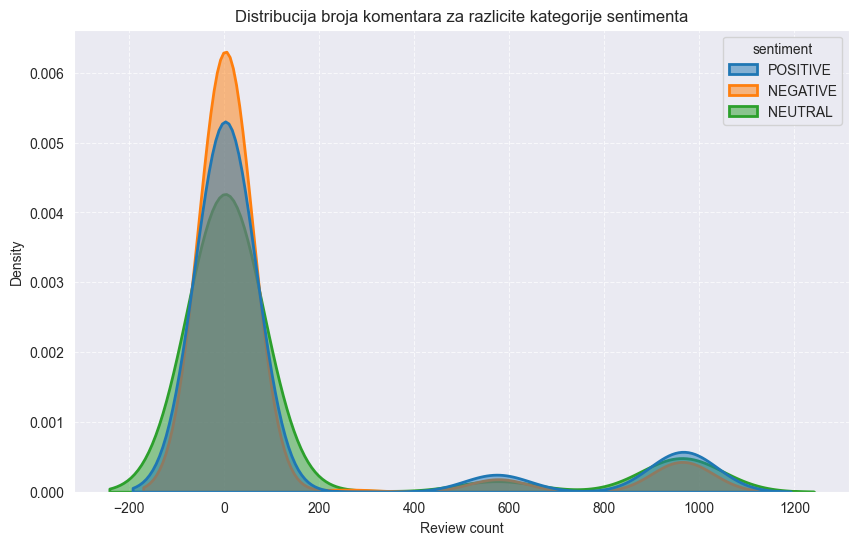

In [10]:
# rating_count

plt.figure(figsize=(10, 6))

sb.kdeplot(data=data,
           x='rating_count',
           hue='sentiment',
           fill=True,
           common_norm=False,
           alpha=0.5,
           linewidth=2)

plt.title('Distribucija broja komentara za razlicite kategorije sentimenta')
plt.xlabel('Review count')
plt.ylabel('Density')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

Varijabla `rating_count` ima slicnu raspodelu za sve klase sentimenata -> necemo je koristi kao prediktor.

Na kraju, jedini prediktor ce biti varijabla `review`.

#### PODELA PODATAKA NA TRAIN I TEST

In [11]:
X = data.review
y = data.sentiment

# logisticka regresija zahteva sve numericke vrednosti!
y_encodings, y_levels = pd.factorize(y)

X_train, X_test, y_train, y_test = train_test_split(X, y_encodings, test_size=0.2, random_state=RAND_STATE,
                                                    stratify=y_encodings)

#### PRETPROCESIRANJE TEKSTA

In [12]:
spacy_model = spacy.load(SPACY_MODEL, disable=['parser', 'ner'])

In [13]:
def spacy_preprocessing(doc):
    tokens = spacy_model(doc)

    tokens = [token for token in tokens
              if ((not token.is_punct) and (not token.is_space)
                  and (not token.like_num) and (not token.like_url))]

    tokens = [token for token in tokens if ((not token.is_stop) or token.lemma_.lower() == 'not')]

    words = [token.lemma_.lower() for token in tokens]

    return words

In [14]:
def create_tfidf_vectorizer(ngram=(1, 2), max_features=-1):
    vectorizer = TfidfVectorizer(
        tokenizer=spacy_preprocessing,
        token_pattern=None,
        ngram_range=ngram,
        max_features=max_features if max_features > 0 else None
    )
    return vectorizer

#### KREIRANJE KLASIFIKATORA

In [15]:
lr_classifier = LogisticRegression(random_state=RAND_STATE, max_iter=2000)

#### KREIRANJE I TRENING PIPELINE-a

In [16]:
vectorizer = create_tfidf_vectorizer()

smote = SMOTE(random_state=RAND_STATE)

lr_pipe = Pipeline(
    steps=[
        ('vectorizer', vectorizer),
        ('smote', smote),
        ('classifier', lr_classifier)
    ],
    verbose=True
)

lr_pipe.fit(X_train, y_train)

[Pipeline] ........ (step 1 of 3) Processing vectorizer, total=  13.9s
[Pipeline] ............. (step 2 of 3) Processing smote, total=   0.1s
[Pipeline] ........ (step 3 of 3) Processing classifier, total=   0.6s


,steps,"[('vectorizer', ...), ('smote', ...), ...]"
,transform_input,None
,memory,None
,verbose,True
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",None
,"lowercase lowercase: bool, default=TrueConvert all characters to lowercase before tokenizing.",True
,"preprocessor preprocessor: callable, default=NoneOverride the preprocessing (string transformation) stage whilepreserving the tokenizing and n-grams generation steps.Only applies if ``analyzer`` is not callable.",None
,"tokenizer tokenizer: callable, default=NoneOverride the string tokenization step while preserving thepreprocessing and n-grams generation steps.Only applies if ``analyzer == 'word'``.",<function spa...0019D51C50EA0>


#### EVALUACIJA MODELA

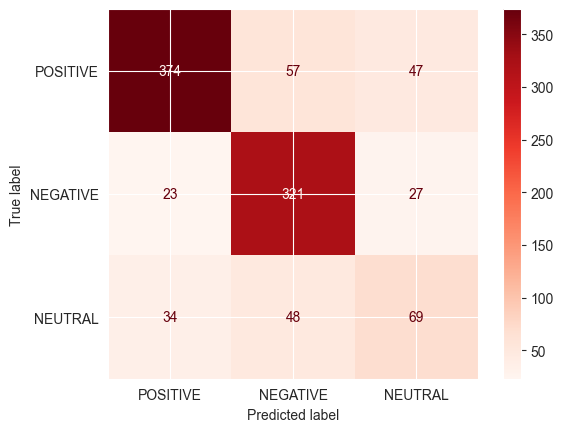

In [17]:
disp = ConfusionMatrixDisplay.from_estimator(
    estimator=lr_pipe,
    X=X_test,
    y=y_test,
    display_labels=y_levels,
    cmap='Reds'
)

In [18]:
lr_pred = lr_pipe.predict(X_test)

lr_report = classification_report(y_true=y_test, y_pred=lr_pred, target_names=y_levels)

print(lr_report)

              precision    recall  f1-score   support

    POSITIVE       0.87      0.78      0.82       478
    NEGATIVE       0.75      0.87      0.81       371
     NEUTRAL       0.48      0.46      0.47       151

    accuracy                           0.76      1000
   macro avg       0.70      0.70      0.70      1000
weighted avg       0.77      0.76      0.76      1000



Interpretacija dobijenih metrika:

Klasa `POSITIVE`:
- precision 0.87 -> od svih komentara koje smo predvideli kao pozitivni sentiment (374+23+34) 87% je stvarno bilo pozitivno
- recall 0.78 -> od svih komentara koji su pozitivni sentiment (374+57+47) 78% smo tacno predvideli kao pozitivne
- f1-score 0.82 -> pokazuje dobru balansiranost izmedju precision i recall-a kod predvidjanja pozitivnog sentimenta

Klasa `NEGATIVE`:
- precision 0.75 -> od svih komentara koje smo predvideli kao negativni sentiment (57+321+48) 75% je stvarno bilo negativno
- recall 0.87 -> od svih komentara koji su negativni sentiment (23+321+27) 87% smo tacno predvideli kao negativne
- f1-score 0.81 -> pokazuje dobru balansiranost izmedju precision i recall-a kod predvidjanja negativnog sentimenta

Klasa `NEUTRAL`:
- precision 0.48 -> od svih komentara koje smo predvideli kao neutralni sentiment (47+27+69) 48% je stvarno bilo neutralno
- recall 0.46 -> od svih komentara koji su neutralni sentiment (34+48+69) 46% smo tacno predvideli kao neutralne
- f1-score 0.47 -> pokazuje losu balansiranost izmedju precision i recall-a kod predvidjanja neutralnog sentimenta


`macro avg (f1-score)` 0.70 -> slaba sposobnost modela da razlikuje sentiment komentara korisnika

`weighted avg (f1-score)` 0.76 -> dobra sposobnost modela da razlikuje dominantan sentiment komentara korisnika, posebno pozitivan

#### PODESAVANJE HIPERPARAMETARA

Najvazniji hiperparametar logisticke regresije je parametar `C`. On odredjuje intenzitet regularizacije model (manje vrednosti -> veca regularizacija i sanse za underfitting, vece vrednosti -> manja regularizacija i sanse za overfitting). Njegove najcesce vrednosti su `0.01, 0.1, 1, 10.0, 100.0`

Kada je u pitanju TfidfVectorizer, njegovi najznacajniji parametri i njihove najcesce vrednosti su:
- `min_df` - minimalni broj dokumenata u kojima ngram mora da se nadje, `[0.001, 0.01, 0.05]`
- `max_df` - maksimalni broj dokumenata u kojima ngram mora da se nadje, `[0.8, 0.9, 0.95]`
- `max_feature` - maksimalni broj atributa koji ce biti selektovani, `[1000, 3000, 5000, 20000, 10000, None]`

Zbog ogranicenosti vremena, kros-validaciju cemo uraditi samo za parametre `C` i `min_df` i za njihovih par vrednosti.

In [19]:
param_grid = {'vectorizer__min_df': [0.001, 0.01],
              'classifier__C': [0.01, 1.0, 10.0]}

grid_search = GridSearchCV(estimator=lr_pipe, param_grid=param_grid, scoring='f1_macro', verbose=2, cv=5)

grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 6 candidates, totalling 30 fits
[Pipeline] ........ (step 1 of 3) Processing vectorizer, total=  10.5s
[Pipeline] ............. (step 2 of 3) Processing smote, total=   0.0s
[Pipeline] ........ (step 3 of 3) Processing classifier, total=   0.0s
[CV] END .......classifier__C=0.01, vectorizer__min_df=0.001; total time=  13.2s
[Pipeline] ........ (step 1 of 3) Processing vectorizer, total=  10.5s
[Pipeline] ............. (step 2 of 3) Processing smote, total=   0.0s
[Pipeline] ........ (step 3 of 3) Processing classifier, total=   0.0s
[CV] END .......classifier__C=0.01, vectorizer__min_df=0.001; total time=  13.2s
[Pipeline] ........ (step 1 of 3) Processing vectorizer, total=  10.5s
[Pipeline] ............. (step 2 of 3) Processing smote, total=   0.0s
[Pipeline] ........ (step 3 of 3) Processing classifier, total=   0.0s
[CV] END .......classifier__C=0.01, vectorizer__min_df=0.001; total time=  13.1s
[Pipeline] ........ (step 1 of 3) Processing vectorizer, t

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step... verbose=True)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__C': [0.01, 1.0, ...], 'vectorizer__min_df': [0.001, 0.01]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_macro'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : the score is

In [20]:
print('Najbolji hiperparametri:', grid_search.best_params_)
print('Najbolji score:', grid_search.best_score_)

Najbolji hiperparametri: {'classifier__C': 1.0, 'vectorizer__min_df': 0.001}
Najbolji score: 0.6855625418852654


#### PONOVNI TRENING I EVALUACIJA MODELA SA NOVIM HIPERPARAMETRIMA

In [21]:
best_C = grid_search.best_params_['classifier__C']
best_mindf = grid_search.best_params_['vectorizer__min_df']

lr_pipe.set_params(classifier__C=best_C, vectorizer__min_df=best_mindf)

lr_pipe.fit(X_train, y_train)

[Pipeline] ........ (step 1 of 3) Processing vectorizer, total=  12.9s
[Pipeline] ............. (step 2 of 3) Processing smote, total=   0.1s
[Pipeline] ........ (step 3 of 3) Processing classifier, total=   0.1s


,steps,"[('vectorizer', ...), ('smote', ...), ...]"
,transform_input,None
,memory,None
,verbose,True
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",None
,"lowercase lowercase: bool, default=TrueConvert all characters to lowercase before tokenizing.",True
,"preprocessor preprocessor: callable, default=NoneOverride the preprocessing (string transformation) stage whilepreserving the tokenizing and n-grams generation steps.Only applies if ``analyzer`` is not callable.",None
,"tokenizer tokenizer: callable, default=NoneOverride the string tokenization step while preserving thepreprocessing and n-grams generation steps.Only applies if ``analyzer == 'word'``.",<function spa...0019D51C50EA0>


In [22]:
lr_pred_opt = lr_pipe.predict(X_test)

lr_report_opt = classification_report(y_true=y_test, y_pred=lr_pred_opt, target_names=y_levels)

print(lr_report_opt)

              precision    recall  f1-score   support

    POSITIVE       0.87      0.77      0.81       478
    NEGATIVE       0.76      0.84      0.80       371
     NEUTRAL       0.40      0.45      0.42       151

    accuracy                           0.74      1000
   macro avg       0.68      0.68      0.68      1000
weighted avg       0.76      0.74      0.75      1000



#### UPOREDJIVANJE MODELA

In [23]:
def get_model_metrics(y_true: np.ndarray, y_pred: np.ndarray, model_name: str):
    # compute P, R, F1 for both averages
    report = classification_report(y_true, y_pred, output_dict=True)

    # compute balanced accuracy
    b_acc = balanced_accuracy_score(y_true, y_pred)

    # extract metrics for the specified averages
    macro_avg = report['macro avg']
    weighted_avg = report['weighted avg']

    results = {
        'Model': model_name,
        'Macro Precision': macro_avg['precision'],
        'Macro Recall': macro_avg['recall'],
        'Macro F1-Score': macro_avg['f1-score'],
        'Weighted Precision': weighted_avg['precision'],
        'Weighted Recall': weighted_avg['recall'],
        'Weighted F1-Score': weighted_avg['f1-score'],
        'Balanced Accuracy': b_acc
    }

    return results

In [24]:
model_predictions = {
    'TF-IDF-LR': lr_pred,
    'TF-IDF-LR-OPT': lr_pred_opt
}

all_results=list()

for model_name, model_pred in model_predictions.items():
    model_res = get_model_metrics(y_test, model_pred, model_name)
    all_results.append(model_res)

all_results_df = pd.DataFrame(all_results)
all_results_df.set_index("Model", inplace=True)
all_results_df = all_results_df.apply(lambda x: round(x,4))

print(all_results_df)

               Macro Precision  Macro Recall  Macro F1-Score  \
Model                                                          
TF-IDF-LR               0.7013        0.7015          0.6993   
TF-IDF-LR-OPT           0.6754        0.6839          0.6774   

               Weighted Precision  Weighted Recall  Weighted F1-Score  \
Model                                                                   
TF-IDF-LR                  0.7672            0.764             0.7631   
TF-IDF-LR-OPT              0.7575            0.744             0.7484   

               Balanced Accuracy  
Model                             
TF-IDF-LR                 0.7015  
TF-IDF-LR-OPT             0.6839  


Model sa podesenim hiperparametrima nije dao bolje rezultate u odnosu na pocetni.